# Algoritmo genético con demanda real

## Procedencia y correspondencia con el examen
La instantánea deriva de **UCI Online Retail**, producto 85123A, bajo CC BY 4.0. Se preservan la decisión entera, codificación binaria y primera generación; se reemplaza la parábola sintética por aptitud inversa al MAE sobre demanda real.

In [1]:
from pathlib import Path
import json, sys, tempfile
import pandas as pd
from IPython.display import display, Image
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from genetic_algorithm import RetailDataset, DemandProblem, Individual, GeneticAlgorithm, GenerationTrace, run_exercise

## Teoría y fases
Para cada lote entero $x$, el cromosoma usa cinco bits. La aptitud es $1/(1+MAE)$; luego se aplican selección por torneo, cruce de un punto, mutación por bit y reemplazo elitista.

,fase,operación
0,Preparación de demanda,"Filtrar ventas válidas, agregar por día, recor..."
1,Codificación binaria,Representar cada lote entero x como cromosoma ...
2,Aptitud inicial,Calcular MAE(x)=promedio(|x-d_t|) y fitness=1/...
3,Selección por torneo,Elegir en cada par el individuo con mayor apti...
4,Cruce de un punto,Intercambiar sufijos después del tercer bit.
5,Mutación,Invertir cada bit cuando el sorteo uniforme es...
6,Reemplazo elitista,Conservar los dos mejores padres e incorporar ...
7,Comparación,Comparar la mejor aptitud antes y después de u...


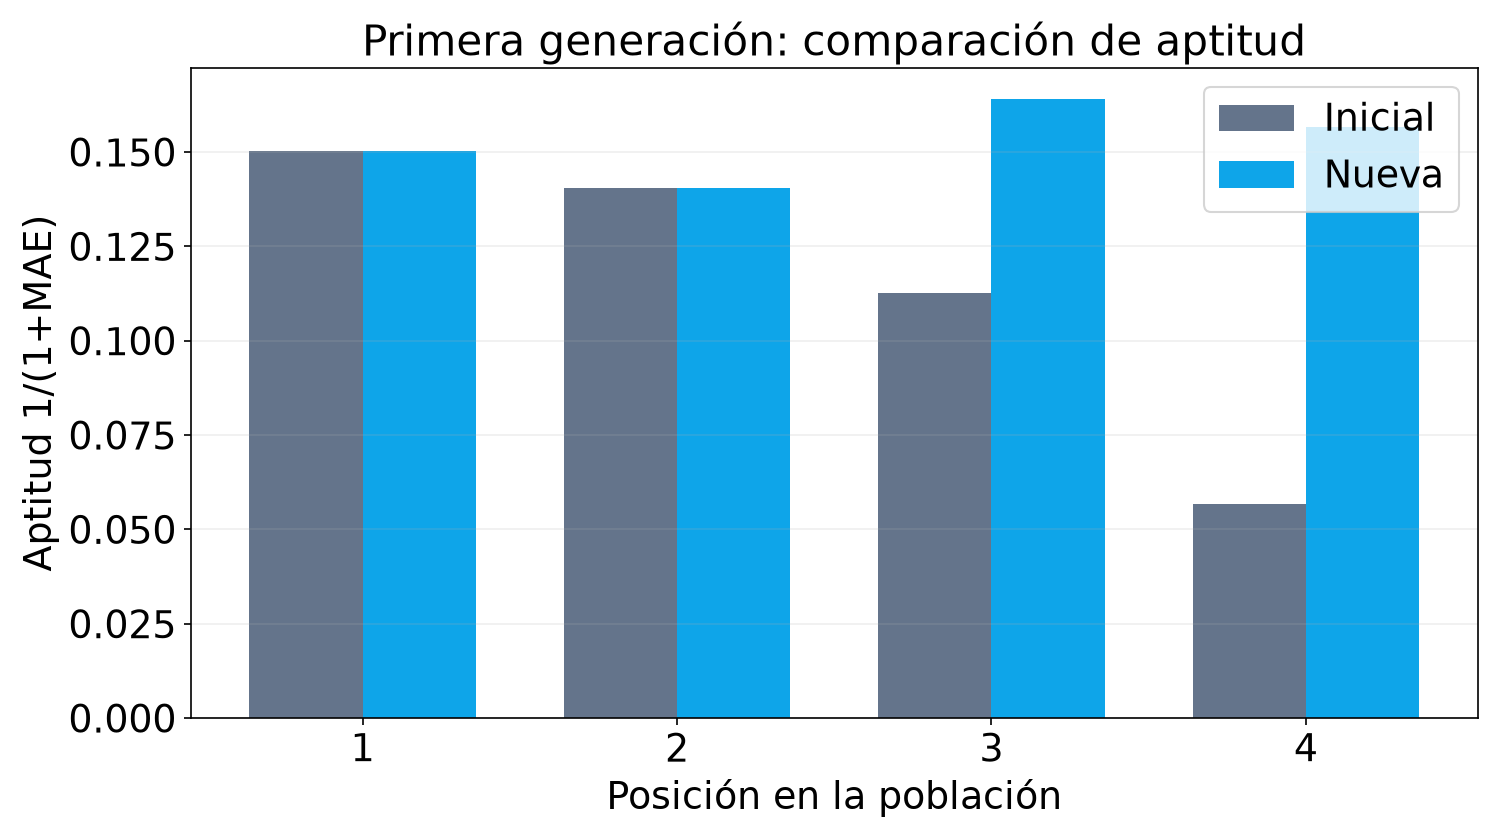

In [2]:
temporary = tempfile.TemporaryDirectory()
manifest = run_exercise(ROOT / "data/derived/online_retail_85123a_daily.csv", ROOT / "data/metadata/genetic.json", ROOT / "configs/genetic.json", Path(temporary.name))
display(pd.DataFrame([{"fase": stage["title_es"], "operación": stage["operation"]} for stage in manifest["stages"]]))
display(Image(filename=str(Path(temporary.name) / "generation_comparison.png")))

## Responsabilidades OOP
`RetailDataset` valida y carga; `DemandProblem` define MAE y aptitud; `Individual` codifica; `GeneticAlgorithm` aplica operadores; `GenerationTrace` conserva la evidencia. El notebook no reimplementa estas responsabilidades.

In [3]:
display(pd.DataFrame(manifest["stages"][2]["outputs"]["individuals"]))
display(pd.DataFrame(manifest["pdf_mapping"]))
print(manifest["summary"]["conclusion_es"])

,value,bits,mae,fitness
0,4,00100,5.655738,0.150246
1,11,01011,6.118033,0.140488
2,14,01110,7.872131,0.112712
3,25,11001,16.642623,0.056681


,pdf_element,original_value,treatment,replacement,justification
0,variable_entera,cantidad a producir,retained,lote diario en docenas,Se conserva una decisión entera de producción.
1,funcion_objetivo,x(15-x),replaced,"1/(1+MAE(x, demanda_real))",El dataset no contiene costos; la cercanía a d...
2,rango_codificacion,"0–15, 4 bits",replaced,"0–31, 5 bits",El máximo de 28 docenas requiere cinco bits.
3,probabilidad_mutacion,0.05,retained,0.05,Es compatible con la codificación binaria didá...
4,etapas_primera_generacion,"aptitud, selección, cruce, mutación y comparación",retained,traza completa,Son las etapas evaluadas en el enunciado.


La mejor solución pasa de 4 a 7 docenas y mejora la aptitud 9.20%.


## Conclusión y limitaciones
La primera generación mejora la aptitud y alcanza el lote central de la demanda. Es una demostración pedagógica: la mediana minimiza MAE directamente y el objetivo no representa beneficio contable.

In [4]:
canonical = json.loads((ROOT / "results/genetic/result.json").read_text(encoding="utf-8"))
assert manifest == canonical
print("Paridad verificada: notebook = manifiesto genético canónico")

Paridad verificada: notebook = manifiesto genético canónico
